# Automobile Data Cleaning, String Manipulation, and Neon PostgreSQL

This project applies the Cars section's cleaning concepts and the Billboard
section's string methods to a different automobile dataset. It inspects missing
data and duplicates, converts text measurements, documents imputation decisions,
visualizes results, exports reproducible outputs, and stores the results in Neon.

Dataset: [CarDekho Vehicle Dataset, Nehal Birla](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho),
file **Car details v3.csv**, supplied locally. The raw file contains 8,128 rows
and 13 columns. Advertised selling prices are in Indian rupees (INR).
This is a historical used-car dataset, not a current market valuation.


## 1. Setup and reproducibility
Use Python 3.10 or later. In a terminal, create a virtual environment and run
`python -m pip install -r requirements.txt`. Select that environment as the
notebook kernel. Keep the notebook beside `data/` and `src/`.

The local cleaning sections work without database credentials. To enable Neon,
copy `.env.example` to `.env` and paste your own PostgreSQL connection URL.
Never put the URL directly into a notebook cell. The database section uploads
automatically when a valid URL is configured.


In [131]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.impute as sk_impute
import sys

RAW_PATH = Path("../data/raw/car_details_v3.csv")
PROJECT_ROOT = Path("..").resolve()

if not RAW_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {RAW_PATH.resolve()}")

PROCESSED = PROJECT_ROOT / "data" / "processed"

PROCESSED.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Dataset found:", RAW_PATH.resolve())

Dataset found: C:\Users\Lenovo\Documents\Foundations of Machine Learning Frameworks\Class Assignment\cleaning-imputation-outliers\data\raw\car_details_v3.csv


## 2. Load and inspect the original data
`cars_raw` preserves the values loaded from the CSV. `source_row` is a lineage
field: it records the original data-row position (CSV line minus one). It is not
a vehicle identifier. The original bytes remain unchanged in `data/raw/`.


In [132]:
cars_raw = pd.read_csv(RAW_PATH)
required_columns = ["name", "year", "selling_price", "km_driven", "fuel", "seller_type",
                    "transmission", "owner", "mileage", "engine", "max_power", "torque", "seats"]
if list(cars_raw.columns) != required_columns:
    raise ValueError("Unexpected source columns; review this version before cleaning.")
print("Rows and columns:", cars_raw.shape)
display(cars_raw.head())
cars_raw.info()
display(cars_raw.describe(include="all").T)


Rows and columns: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,7907,393,18.9 kmpl,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,7907,121,1248 CC,1017,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data dictionary

| Column | Meaning | Treatment |
|---|---|---|
| name | Manufacturer, model, and variant | Keep raw; normalize whitespace; derive brand/model |
| year | Listed vehicle year | Validate; retain |
| selling_price | Listed selling price, INR | Validate positive; retain |
| km_driven | Total distance travelled, kilometres | Validate nonnegative; retain |
| fuel | Petrol, Diesel, CNG, or LPG | Standardize text case |
| seller_type | Seller category | Standardize text case and spacing |
| transmission | Manual or Automatic | Standardize text case and spacing |
| owner | Ownership category | Standardize text case and spacing |
| mileage | Fuel economy, not odometer distance | Extract value and unit separately |
| engine | Engine displacement with CC suffix | Derive numeric engine_cc |
| max_power | Engine power with bhp suffix | Derive numeric max_power_bhp |
| torque | Torque and RPM in inconsistent formats | Preserve; normalize spacing for inspection |
| seats | Seating capacity | Fill missing values using a categorical strategy |

Torque parsing is not forced into a single numeric value: the strings mix
units and RPM ranges. The raw field and `torque_text` remain available; missing
torque values are reported rather than invented.


## 3. Assess missing values and duplicates
`isna()` counts missing entries; `notna()` confirms valid values. Counts below
describe the original data before any rows are excluded.


In [133]:
missing_before = pd.DataFrame({
    "missing_count": cars_raw.isna().sum(),
    "missing_percent": (cars_raw.isna().mean() * 100).round(2),
    "non_missing_count": cars_raw.notna().sum(),
})
display(missing_before)
print("Repeated rows after the first occurrence:", cars_raw.duplicated().sum())
display(cars_raw.loc[cars_raw.duplicated(keep=False)].head(6))


,missing_count,missing_percent,non_missing_count
name,0,0.00,8128
year,0,0.00,8128
selling_price,0,0.00,8128
km_driven,0,0.00,8128
fuel,0,0.00,8128
seller_type,0,0.00,8128
transmission,0,0.00,8128
owner,0,0.00,8128
mileage,221,2.72,7907
engine,221,2.72,7907


Repeated rows after the first occurrence: 1202


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
31,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
32,Maruti Omni 8 Seater BSIV,2012,150000,35000,Petrol,Individual,Manual,Second Owner,14.0 kmpl,796 CC,35 bhp,6.1kgm@ 3000rpm,5.0
33,Hyundai i20 1.2 Asta Dual Tone,2018,730000,2388,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
34,Maruti Vitara Brezza LDi,2017,650000,16200,Diesel,Individual,Manual,First Owner,24.3 kmpl,1248 CC,88.5 bhp,200Nm@ 1750rpm,5.0
35,Maruti Alto 800 CNG LXI Optional,2019,330000,10000,CNG,Individual,Manual,Second Owner,33.44 km/kg,796 CC,40.3 bhp,60Nm@ 3500rpm,4.0
36,Maruti Alto K10 VXI Airbag,2019,366000,15000,Petrol,Individual,Manual,First Owner,23.95 kmpl,998 CC,67.1 bhp,90Nm@ 3500rpm,5.0


## 4. Create a working copy and treat repeated rows
For this exercise, exact repeated records are treated as duplicate listings and
one copy is retained. Matching attributes cannot prove two rows refer to the
same physical vehicle because there is no listing ID or VIN. This assumption
may remove distinct cars with identical recorded attributes, so the original
CSV, raw database table, and excluded rows are retained for review.

The duplicate comparison uses the original 13 columns, excluding `source_row`.


In [134]:
# Remove Duplicate Records and Create the Working Copy

duplicate_mask = cars_raw.duplicated(keep="first")

# Retained in memory for the existing validation checks.
duplicate_rows = cars_raw.loc[duplicate_mask].copy()

cars_clean = cars_raw.loc[~duplicate_mask].copy()

# Preserve each retained record's original row position.
cars_clean.insert(0, "source_row", cars_clean.index + 1)

print("Original records:", len(cars_raw))
print("Duplicates removed:", len(duplicate_rows))
print("Retained records:", len(cars_clean))

Original records: 8128
Duplicates removed: 1202
Retained records: 6926


## 5. Clean text and extract manufacturer/model
String operations include `.str.strip()`, `.str.replace()`, `.str.lower()`,
`.str.upper()`, `.str.title()`, `.str.extract()`, and `.str.contains()`.
Normalizing already-consistent text may leave it unchanged; no artificial
errors are added. Original source columns remain available for comparison.

A first-word split alone would misclassify **Land Rover** and **Ashok Leyland**.
These multiword manufacturers are handled explicitly.


In [135]:
def tidy_text(series):
    return series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

cars_clean["name_clean"] = tidy_text(cars_clean["name"])
cars_clean["fuel_clean"] = tidy_text(cars_clean["fuel"]).str.upper()
cars_clean["seller_type_clean"] = tidy_text(cars_clean["seller_type"]).str.lower()
cars_clean["transmission_clean"] = tidy_text(cars_clean["transmission"]).str.lower()
cars_clean["owner_clean"] = tidy_text(cars_clean["owner"]).str.lower()
cars_clean["torque_text"] = tidy_text(cars_clean["torque"]).str.lower()

brand_pattern = r"^(Land Rover|Ashok Leyland|\S+)\s*(.*)$"
parts = cars_clean["name_clean"].str.extract(brand_pattern)
cars_clean["brand"] = parts[0]
cars_clean["model"] = parts[1].str.strip()
display(cars_clean[["name", "brand", "model", "fuel_clean"]].head())
display(cars_clean.loc[cars_clean["name_clean"].str.contains(
    r"^(?:Land Rover|Ashok Leyland)\b", regex=True, na=False), ["name", "brand", "model"]])


,name,brand,model,fuel_clean
0,Maruti Swift Dzire VDI,Maruti,Swift Dzire VDI,DIESEL
1,Skoda Rapid 1.5 TDI Ambition,Skoda,Rapid 1.5 TDI Ambition,DIESEL
2,Honda City 2017-2020 EXi,Honda,City 2017-2020 EXi,PETROL
3,Hyundai i20 Sportz Diesel,Hyundai,i20 Sportz Diesel,DIESEL
4,Maruti Swift VXI BSIII,Maruti,Swift VXI BSIII,PETROL


,name,brand,model
135,Land Rover Discovery Sport TD4 SE,Land Rover,Discovery Sport TD4 SE
2137,Land Rover Freelander 2 TD4 HSE,Land Rover,Freelander 2 TD4 HSE
4011,Ashok Leyland Stile LE,Ashok Leyland,Stile LE
6724,Land Rover Range Rover Evoque 2.2L Pure,Land Rover,Range Rover Evoque 2.2L Pure


## 6. Convert engine capacity and power strings to numbers
`pd.to_numeric(errors="coerce")` converts invalid numeric text to a missing
value. A power entry containing only `bhp` is missing information, not zero.
A zero power or zero fuel-economy value is treated as an invalid placeholder
for an operating car and is changed to missing in the derived numeric field.
Original values and Boolean flags preserve the evidence.


In [136]:
engine_text = tidy_text(cars_clean["engine"]).str.lower()
power_text = tidy_text(cars_clean["max_power"]).str.lower()
cars_clean["engine_cc"] = pd.to_numeric(
    engine_text.str.replace("cc", "", regex=False).str.strip(), errors="coerce").astype("float64")
cars_clean["max_power_bhp"] = pd.to_numeric(
    power_text.str.replace("bhp", "", regex=False).str.strip(), errors="coerce").astype("float64")
cars_clean["engine_invalid_nonpositive"] = cars_clean["engine_cc"].le(0)
cars_clean["power_invalid_nonpositive"] = cars_clean["max_power_bhp"].le(0)
cars_clean.loc[cars_clean["engine_invalid_nonpositive"], "engine_cc"] = np.nan
cars_clean.loc[cars_clean["power_invalid_nonpositive"], "max_power_bhp"] = np.nan
display(cars_clean[["engine", "engine_cc", "max_power", "max_power_bhp"]].head())
print("Missing power after parsing:", cars_clean["max_power_bhp"].isna().sum())


,engine,engine_cc,max_power,max_power_bhp
0,1248 CC,1248.0,74 bhp,74.00
1,1498 CC,1498.0,103.52 bhp,103.52
2,1497 CC,1497.0,78 bhp,78.00
3,1396 CC,1396.0,90 bhp,90.00
4,1298 CC,1298.0,88.2 bhp,88.20


Missing power after parsing: 209


## 7. Separate fuel economy values from their units
`kmpl` means kilometres per litre; `km/kg` means kilometres per kilogram.
These units are not directly interchangeable and are never averaged together.
A full-string pattern rejects unrecognized measurements instead of silently
extracting an unrelated number.

For a missing unit, use a fuel-to-unit mapping only where the observed data
contains exactly one unit for that fuel. Such inferred units are flagged.


In [137]:
mileage_text = tidy_text(cars_clean["mileage"]).str.lower()
mileage_parts = mileage_text.str.extract(r"^(\d+(?:\.\d+)?)\s*(kmpl|km/kg)$")
cars_clean["fuel_economy_value"] = pd.to_numeric(mileage_parts[0], errors="coerce").astype("float64")
cars_clean["fuel_economy_unit"] = mileage_parts[1].astype("string")
cars_clean["economy_invalid_nonpositive"] = cars_clean["fuel_economy_value"].le(0)
cars_clean.loc[cars_clean["economy_invalid_nonpositive"], "fuel_economy_value"] = np.nan
observed_unit_counts = cars_clean.groupby("fuel_clean")["fuel_economy_unit"].nunique()
single_unit_fuels = observed_unit_counts[observed_unit_counts.eq(1)].index
unit_lookup = (cars_clean.loc[cars_clean["fuel_clean"].isin(single_unit_fuels)]
               .dropna(subset=["fuel_economy_unit"])
               .groupby("fuel_clean")["fuel_economy_unit"].first())
missing_unit = cars_clean["fuel_economy_unit"].isna()
inferred_units = cars_clean["fuel_clean"].map(unit_lookup)
cars_clean["fuel_economy_unit_inferred"] = missing_unit & inferred_units.notna()
cars_clean["fuel_economy_unit"] = cars_clean["fuel_economy_unit"].fillna(inferred_units)
display(cars_clean[["mileage", "fuel_economy_value", "fuel_economy_unit"]].head(10))
display(pd.crosstab(cars_clean["fuel_clean"], cars_clean["fuel_economy_unit"]))


,mileage,fuel_economy_value,fuel_economy_unit
0,23.4 kmpl,23.40,kmpl
1,21.14 kmpl,21.14,kmpl
2,17.7 kmpl,17.70,kmpl
3,23.0 kmpl,23.00,kmpl
4,16.1 kmpl,16.10,kmpl
5,20.14 kmpl,20.14,kmpl
6,17.3 km/kg,17.30,km/kg
7,16.1 kmpl,16.10,kmpl
8,23.59 kmpl,23.59,kmpl
9,20.0 kmpl,20.00,kmpl


fuel_economy_unit,km/kg,kmpl
fuel_clean,,
CNG,56,0
DIESEL,0,3755
LPG,38,0
PETROL,0,3077


## 8. Validate essential numerical fields
Year, price, and distance are converted explicitly. Rows without a positive
price, plausible year, or nonnegative odometer reading are excluded and saved
separately. These are validity checks, not a rule for removing statistical
outliers. A small positive odometer value is not automatically invalid.


In [138]:
import datetime
import numpy as np
for col in ["year", "selling_price", "km_driven", "seats"]:
    cars_clean[col] = pd.to_numeric(cars_clean[col], errors="coerce")
current_year = datetime.datetime.now(datetime.timezone.utc).year
valid_essential = (
    cars_clean["year"].between(1886, current_year + 1)
    & cars_clean["selling_price"].gt(0)
    & cars_clean["km_driven"].ge(0)
).fillna(False)
invalid_rows = cars_clean.loc[~valid_essential].copy()
cars_clean = cars_clean.loc[valid_essential].copy()
cars_clean["year"] = cars_clean["year"].astype("int64")
cars_clean["km_driven"] = cars_clean["km_driven"].astype("int64")
# Seats are a discrete count; invalid or fractional counts become missing.
valid_seats = cars_clean["seats"].gt(0) & cars_clean["seats"].mod(1).eq(0)
cars_clean.loc[~valid_seats, "seats"] = np.nan
print("Rows excluded by essential-field validity checks:", len(invalid_rows))


Rows excluded by essential-field validity checks: 0


## 9. Compare missing-value strategies before choosing
`dropna()` can discard observations, and `dropna(axis=1)` can discard useful
features. Mean imputation is sensitive to extreme values. Median imputation
uses a central observed value and is suitable here for skewed measurements.
Mode is appropriate for discrete seat counts. These are demonstrations on
copies; the final strategy is implemented in the following section.
`SimpleImputer` also demonstrates a reusable scikit-learn median strategy.


In [139]:
before_imputation = cars_clean.copy()
numeric_fields = ["engine_cc", "max_power_bhp", "fuel_economy_value", "seats"]
display(before_imputation[numeric_fields].isna().sum().rename("missing_before_imputation"))
comparison = pd.DataFrame([
    {"strategy": "Keep all rows", "rows_retained": len(before_imputation)},
    {"strategy": "Drop rows missing any selected numeric field",
     "rows_retained": len(before_imputation.dropna(subset=numeric_fields))},
])
display(comparison)
print("Columns if every column with missing data were dropped:",
      before_imputation.dropna(axis=1).shape[1], "of", before_imputation.shape[1])
engine_mean_demo = before_imputation["engine_cc"].fillna(before_imputation["engine_cc"].mean())
engine_median_demo = before_imputation["engine_cc"].fillna(before_imputation["engine_cc"].median())
seat_mode = before_imputation["seats"].mode().iloc[0]
seats_mode_demo = before_imputation["seats"].fillna(seat_mode)
simple_imputer = sk_impute.SimpleImputer(strategy="median")
simple_engine_demo = simple_imputer.fit_transform(before_imputation[["engine_cc"]]).ravel()
display(pd.DataFrame({
    "engine_original": before_imputation["engine_cc"],
    "engine_mean_demo": engine_mean_demo,
    "engine_median_demo": engine_median_demo,
    "engine_simple_imputer_demo": simple_engine_demo,
    "seats_mode_demo": seats_mode_demo,
}).loc[before_imputation["engine_cc"].isna()].head())
print("Overall engine mean / median:", round(before_imputation["engine_cc"].mean(), 2),
      before_imputation["engine_cc"].median())


engine_cc             208
max_power_bhp         209
fuel_economy_value    223
seats                 208
Name: missing_before_imputation, dtype: int64

,strategy,rows_retained
0,Keep all rows,6926
1,Drop rows missing any selected numeric field,6702


Columns if every column with missing data were dropped: 21 of 30


,engine_original,engine_mean_demo,engine_median_demo,engine_simple_imputer_demo,seats_mode_demo
13,NaN,1430.891337,1248.0,1248.0,5.0
31,NaN,1430.891337,1248.0,1248.0,5.0
78,NaN,1430.891337,1248.0,1248.0,5.0
87,NaN,1430.891337,1248.0,1248.0,5.0
119,NaN,1430.891337,1248.0,1248.0,5.0


Overall engine mean / median: 1430.89 1248.0


## 10. Apply and flag the selected imputation strategy
Engine capacity and power use manufacturer-and-fuel medians, falling back to
fuel median and then overall median. Fuel economy uses manufacturer, fuel,
and unit groups, falling back to fuel/unit and then unit. It never falls back
to a median mixing kilometres per litre and kilometres per kilogram.
Seats use manufacturer mode with overall-mode fallback; ties choose the
smallest mode deterministically. Every filled field has an imputation flag.

These replacements are estimates, not recovered true measurements. This is
an exploratory cleaning project. If a prediction model is added, fit all
imputation values on training data only, then apply them to validation/test data.


In [140]:
def hierarchical_median(frame, column, levels):
    result = frame[column].copy()
    for group_columns in levels:
        estimates = frame.groupby(group_columns, dropna=False)[column].transform("median")
        result = result.fillna(estimates)
    return result

for col in ["engine_cc", "max_power_bhp"]:
    missing = cars_clean[col].isna()
    filled = hierarchical_median(cars_clean, col, [["brand", "fuel_clean"], ["fuel_clean"]])
    cars_clean[col] = filled.fillna(cars_clean[col].median())
    cars_clean[col + "_imputed"] = missing & cars_clean[col].notna()

missing_economy = cars_clean["fuel_economy_value"].isna()
cars_clean["fuel_economy_value"] = hierarchical_median(
    cars_clean, "fuel_economy_value", [
        ["brand", "fuel_clean", "fuel_economy_unit"],
        ["fuel_clean", "fuel_economy_unit"], ["fuel_economy_unit"],
    ])
cars_clean["fuel_economy_value_imputed"] = missing_economy & cars_clean["fuel_economy_value"].notna()

def smallest_mode(values):
    modes = values.mode()
    return modes.iloc[0] if not modes.empty else np.nan

missing_seats = cars_clean["seats"].isna()
cars_clean["seats_count"] = (cars_clean["seats"].fillna(
    cars_clean.groupby("brand")["seats"].transform(smallest_mode)
).fillna(smallest_mode(cars_clean["seats"])).astype("int64"))
cars_clean["seats_count_imputed"] = missing_seats
final_numeric = ["engine_cc", "max_power_bhp", "fuel_economy_value", "seats_count"]
imputation_flags = [col + "_imputed" for col in final_numeric]
display(cars_clean[imputation_flags].sum().rename("values_imputed"))
display(cars_clean[["brand", "engine_cc", "max_power_bhp", "fuel_economy_value", "seats_count"]].head())


engine_cc_imputed             208
max_power_bhp_imputed         209
fuel_economy_value_imputed    223
seats_count_imputed           208
Name: values_imputed, dtype: int64

,brand,engine_cc,max_power_bhp,fuel_economy_value,seats_count
0,Maruti,1248.0,74.00,23.40,5
1,Skoda,1498.0,103.52,21.14,5
2,Honda,1497.0,78.00,17.70,5
3,Hyundai,1396.0,90.00,23.00,5
4,Maruti,1298.0,88.20,16.10,5


## 11. Inspect potential outliers without automatically deleting them
An IQR flag identifies values outside Q1 - 1.5*IQR to Q3 + 1.5*IQR. An expensive
luxury car can be a valid observation. Price outliers are retained; the flag
supports review and does not label records as errors.


In [141]:
q1, q3 = cars_clean["selling_price"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
cars_clean["price_iqr_flag"] = ~cars_clean["selling_price"].between(lower_bound, upper_bound)
print("Price IQR bounds (INR):", lower_bound, upper_bound)
print("Potential price outliers retained:", cars_clean["price_iqr_flag"].sum())
display(cars_clean.loc[cars_clean["price_iqr_flag"], ["brand", "model", "selling_price"]].head())


Price IQR bounds (INR): -325250.0 1208750.0
Potential price outliers retained: 328


,brand,model,selling_price
41,Jeep,Compass 1.4 Limited Plus BSIV,2100000
47,Toyota,Fortuner 4x4 MT,1500000
49,Mercedes-Benz,B Class B180,1450000
55,Toyota,Innova Crysta 2.8 ZX AT BSIV,1650000
57,Audi,A6 2.0 TDI Technology,1750000


## 12. Visualize and interpret the results
Missingness bars compare derived numeric features immediately before and
after imputation, using the same retained rows. Original text fields may still
contain missing values by design. Manufacturer counts describe this sample,
not market share. Fuel economy is plotted separately by unit.


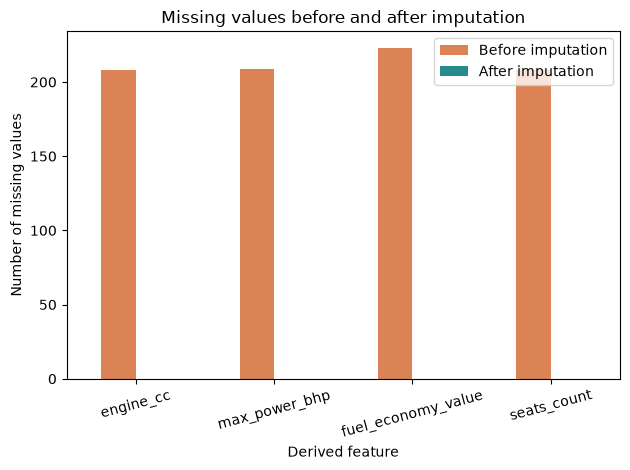

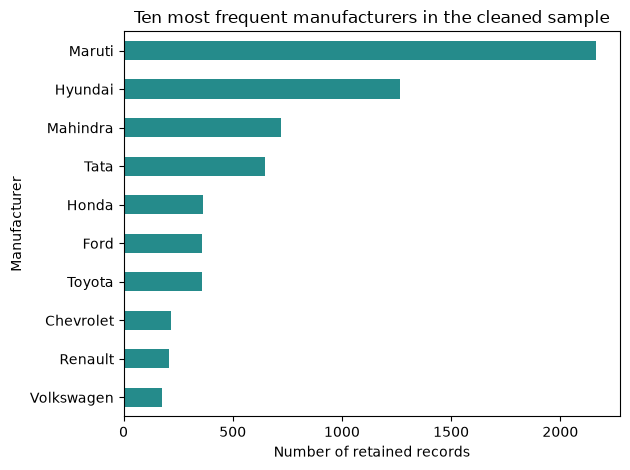

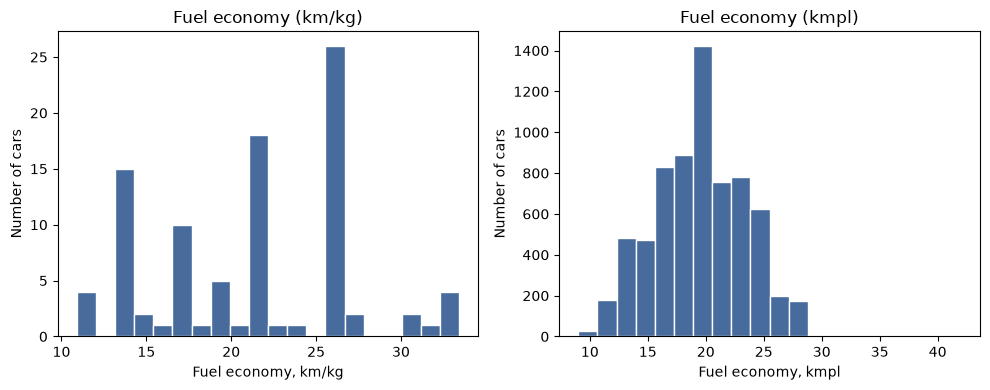

Most frequent manufacturer: Maruti with 2165 records
Missing final numerical values: 0


In [142]:
before_counts = before_imputation[["engine_cc", "max_power_bhp", "fuel_economy_value", "seats"]].isna().sum()
before_counts.index = final_numeric
after_counts = cars_clean[final_numeric].isna().sum()
missing_chart = pd.DataFrame({"Before imputation": before_counts, "After imputation": after_counts})
ax = missing_chart.plot.bar(color=["#dc8355", "#258b8b"], rot=15)
ax.set(title="Missing values before and after imputation", xlabel="Derived feature", ylabel="Number of missing values")
plt.tight_layout()
plt.show()

brand_counts = cars_clean["brand"].value_counts().head(10)
ax = brand_counts.sort_values().plot.barh(color="#258b8b")
ax.set(title="Ten most frequent manufacturers in the cleaned sample", xlabel="Number of retained records", ylabel="Manufacturer")
plt.tight_layout()
plt.show()

units = sorted(cars_clean["fuel_economy_unit"].dropna().unique())
fig, axes = plt.subplots(1, len(units), figsize=(10, 4), squeeze=False)
for ax, unit in zip(axes[0], units):
    values = cars_clean.loc[cars_clean["fuel_economy_unit"].eq(unit), "fuel_economy_value"]
    ax.hist(values, bins=20, color="#466b9c", edgecolor="white")
    ax.set(title=f"Fuel economy ({unit})", xlabel=f"Fuel economy, {unit}", ylabel="Number of cars")
fig.tight_layout()
# fig.savefig(REPORTS / "fuel_economy_by_unit.png", dpi=150)
plt.show()
print("Most frequent manufacturer:", brand_counts.index[0], "with", int(brand_counts.iloc[0]), "records")
print("Missing final numerical values:", int(after_counts.sum()))


## 13. Export, and summarize decisions
These assertions check the intended outcome, including row accounting, unit
separation, positive measurements, integer seats, and manufacturer extraction.
They do not require every original text field to become complete.


In [143]:
# Save Only the Cleaned Dataset

from pathlib import Path

PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

output_file = PROCESSED / "cars_cleaned.csv"
cars_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved:", output_file.resolve())
print("Rows and columns:", cars_clean.shape)

Cleaned dataset saved: C:\Users\Lenovo\Documents\Foundations of Machine Learning Frameworks\Class Assignment\cleaning-imputation-outliers\data\processed\cars_cleaned.csv
Rows and columns: (6926, 36)


## 14. Connect to Neon PostgreSQL
1. Open your Neon project and choose **Connect**. Copy the PostgreSQL URL.
2. Copy `.env.example` to `.env` beside this notebook; replace the placeholder.
3. Run this section after installing `requirements.txt`. If you change the URL
   during a session, restart the kernel and Run All so an older environment
   variable cannot take precedence.

The helper uses SQLAlchemy with the explicit psycopg2 driver and SSL. It creates
the assignment's `cardekho_lab` schema and four tables: `runs`, `raw_cars`,
`clean_cars`, and `cleaning_audit`. A database role with schema-creation/write
permission is required. Use a Neon project you are permitted to write to.

`run_id` is based on the source-file hash and cleaning policy version. Repeating
the same batch reuses its data and verifies row counts. New sources/policies
create new batches. Writes are transactional and use primary/foreign keys.
Increment `POLICY_VERSION` whenever cleaning logic changes so results are not
confused with a previously stored batch.
The helper does not replace any existing table or delete any row.

[Neon SQLAlchemy example](https://neon.com/blog/deploy-a-serverless-fastapi-app-with-neon-postgres-and-aws-app-runner-at-any-scale)
and [SQLAlchemy PostgreSQL/SSL documentation](https://docs.sqlalchemy.org/en/20/dialects/postgresql.html).


In [ ]:
# Upload the Processed CSV to Neon PostgreSQL

from pathlib import Path
import sys

PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.neon_connect import DatabaseManager

processed_file = PROJECT_ROOT / "data" / "processed" / "cars_cleaned.csv"
processed_cars = pd.read_csv(processed_file)

db = DatabaseManager()

try:
    db.upload_dataframe(
        processed_cars,
        "cardekho_clean",
        if_exists="replace"
    )

    # Verify how many records were stored.
    result = db.fetch_dataframe(
        "SELECT COUNT(*) AS total_rows FROM cardekho_clean"
    )

    assert int(result.loc[0, "total_rows"]) == len(processed_cars)

    display(result)

    # Preview the uploaded data.
    display(
        db.fetch_dataframe(
            "SELECT * FROM cardekho_clean LIMIT 5"
        )
    )

    print("Processed CSV uploaded and row count verified.")

finally:
    db.engine.dispose()

✅ Successfully connected to Neon PostgreSQL database.
✅ Successfully uploaded 6926 rows to 'cardekho_clean'.


,total_rows
0,6926


,source_row,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,name_clean,fuel_clean,seller_type_clean,transmission_clean,owner_clean,torque_text,brand,model,engine_cc,max_power_bhp,engine_invalid_nonpositive,power_invalid_nonpositive,fuel_economy_value,fuel_economy_unit,economy_invalid_nonpositive,fuel_economy_unit_inferred,engine_cc_imputed,max_power_bhp_imputed,fuel_economy_value_imputed,seats_count,seats_count_imputed,price_iqr_flag
0,1,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,Maruti Swift Dzire VDI,DIESEL,individual,manual,first owner,190nm@ 2000rpm,Maruti,Swift Dzire VDI,1248.0,74.00,False,False,23.40,kmpl,False,False,False,False,False,5,False,False
1,2,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,Skoda Rapid 1.5 TDI Ambition,DIESEL,individual,manual,second owner,250nm@ 1500-2500rpm,Skoda,Rapid 1.5 TDI Ambition,1498.0,103.52,False,False,21.14,kmpl,False,False,False,False,False,5,False,False
2,3,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,Honda City 2017-2020 EXi,PETROL,individual,manual,third owner,"12.7@ 2,700(kgm@ rpm)",Honda,City 2017-2020 EXi,1497.0,78.00,False,False,17.70,kmpl,False,False,False,False,False,5,False,False
3,4,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,Hyundai i20 Sportz Diesel,DIESEL,individual,manual,first owner,22.4 kgm at 1750-2750rpm,Hyundai,i20 Sportz Diesel,1396.0,90.00,False,False,23.00,kmpl,False,False,False,False,False,5,False,False
4,5,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti Swift VXI BSIII,PETROL,individual,manual,first owner,"11.5@ 4,500(kgm@ rpm)",Maruti,Swift VXI BSIII,1298.0,88.20,False,False,16.10,kmpl,False,False,False,False,False,5,False,False


Processed CSV uploaded and row count verified.


## 15. Inspect the stored tables in the Neon SQL Editor
After a successful connection, the following query shows the most recent
uploaded batch. Queries in Python use bound parameters for `run_id`.

```sql
SELECT run_id, loaded_at, raw_rows, clean_rows
FROM cardekho_lab.runs
ORDER BY loaded_at DESC;

SELECT brand, COUNT(*) AS car_count,
       ROUND(AVG(selling_price)::numeric, 2) AS average_price_inr
FROM cardekho_lab.clean_cars
WHERE run_id = (
    SELECT run_id FROM cardekho_lab.runs
    ORDER BY loaded_at DESC, run_id LIMIT 1
)
GROUP BY brand
ORDER BY car_count DESC, brand;
```


## 16. Observations and reflection
The original file contains 8,128 records with five columns containing missing
values. Removing 1,202 exact repeats under the documented listing assumption
leaves 6,926 records; all pass the essential-field checks. String manipulation
separates measurement values from units, retains multiword manufacturers, and
produces numeric engine capacity, power, and fuel economy. Zero placeholders
are treated as missing, and imputation flags distinguish estimated values from
observed ones. The exported cleaning summary gives the exact counts after
deduplication and parsing. Fuel-economy units remain separate. Potential price
outliers are retained because extreme prices alone do not establish an error.

The missing-value chart shows the selected numerical features are complete
after imputation. The manufacturer chart shows which brands are most frequent
in this sample, while the two fuel-economy histograms show distributions in
their respective units. Imputation can reduce variability, so numerical
completeness should not be interpreted as perfect measurement quality.

Neon provides persistent relational storage and allows SQL analysis without
repeating the cleaning step. Raw, clean, audit, and batch tables preserve the
processing lineage. A local run with no URL does not establish that a database
connection works; only the successful upload and read-back output does.

Limitations include historical advertised prices, nonrepresentative listings,
unverified duplicate identities, estimated missing values, and unresolved torque
formatting. These limitations should be considered before later ML work.


## Submission checklist
- [ ] Restart the kernel and Run All in the configured virtual environment.
- [ ] Review the charts, cleaning summary, and validation output.
- [ ] Configure Neon and obtain successful upload/read-back output.
- [ ] Check all four tables in the Neon SQL Editor.
- [ ] Confirm that a second database run reports an existing verified batch.
- [ ] Include this notebook, README, requirements, `.gitignore`, and permitted data.
- [ ] Keep `.env` and database credentials out of GitHub and screenshots.
- [ ] Follow any additional submission instructions given by the instructor.
